---
title: Landcover Classification (Jawa Timur)
---

## Business Understanding

### Latar Belakang

Pemantauan tutupan dan penggunaan lahan di Jawa Timur masih banyak bergantung pada survei lapangan
dan pemetaan manual yang lambat dan mahal. Citra satelit Sentinel-2 (resolusi 10–20 m, diperbarui
berkala dan gratis) memungkinkan pemetaan permukaan bumi secara otomatis. Proyek ini memetakan
tutupan lahan di seluruh wilayah daratan Jawa Timur menggunakan batas Area of Interest (AoI)
Provinsi Jawa Timur (`jatim_raster.geojson`), yang mencakup enam kelas tutupan lahan: bangunan,
lahan pertanian, badan air, hutan, hutan mangrove, dan lainnya (other).

### Tujuan

1. Memetakan enam kelas tutupan lahan secara otomatis di seluruh wilayah Jawa Timur dari citra Sentinel-2 L2A:
   bangunan, lahan pertanian, badan air, hutan, hutan mangrove, dan lainnya (other).
2. Membedakan mangrove dari hutan biasa menggunakan komposit B8A–B11–B4.
3. Menyajikan hasil dalam peta interaktif dengan filter per kelas serta ringkasan luas dan
   akurasi model.

### Pengguna dan Manfaat

| Pengguna | Manfaat |
|---|---|
| Pemerintah daerah | Dukungan pemantauan lahan dan tata ruang |
| Peneliti | Dasar analisis perubahan tutupan lahan dan konservasi |
| Masyarakat | Informasi yang mudah diakses tentang kondisi lahan di sekitarnya |

## Implementasi

### Mengambil AoI di Wilayah Jawa Timur

#### Import Library

In [3]:
import os, json, time
import requests
import warnings
import openeo
import glob
import rasterio

import numpy as np
import geopandas as gpd

from rasterio.merge import merge
from shapely.geometry import box

#### Autentikasi CDSE

In [4]:
conn = openeo.connect('openeo.dataspace.copernicus.eu').authenticate_oidc()

Authenticated using refresh token.


In [5]:
AOI_PATH = './digitizations/jatim_raster.geojson'
aoi_gdf = gpd.read_file(AOI_PATH)
aoi_geom = aoi_gdf.geometry.unary_union

BANDS = ['B02', 'B03', 'B04', 'B08', 'B8A', 'B11', 'B12']
W, S, E, N = aoi_gdf.total_bounds
NX, NY = 8, 5
TEMPORAL = ['2026-06-01', '2026-09-30']
MAX_CLOUD = 40

JOB_OPTIONS = {
    "executor-memory": "4G",
    "executor-memoryOverhead": "3G",
}

MAX_PARALLEL = 2
MAX_RETRY = 2
STATE_FILE = './other/tiles_state_jatim.json'

xs = np.linspace(W, E, NX + 1)
ys = np.linspace(S, N, NY + 1)

def build_cube(w, s, e, n):
    cube = conn.load_collection(
        'SENTINEL2_L2A',
        spatial_extent={"west": float(w), "south": float(s), "east": float(e), "north": float(n), "crs": "EPSG:4326"},
        temporal_extent=TEMPORAL,
        bands=BANDS + ['SCL'],
        max_cloud_cover=MAX_CLOUD,
    )

    scl = cube.band('SCL')
    bad = (scl == 0) | (scl == 1) | (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10) | (scl == 11)
    cube = cube.mask(bad).filter_bands(BANDS)
    cube = cube.reduce_dimension(dimension='t', reducer='median')
    cube = cube.resample_spatial(resolution=20, projection=32749)
    return cube.save_result(format='GTiff')

TILES = {}
for i in range(NX):
    for j in range(NY):
        tile_box = box(xs[i], ys[j], xs[i + 1], ys[j + 1])
        if aoi_geom.intersects(tile_box):
            TILES[f'tile_{i}_{j}'] = (xs[i], ys[j], xs[i + 1], ys[j + 1])

print(len(TILES), 'ubin (dari', NX * NY, 'total, setelah filter AoI)')


38 ubin (dari 40 total, setelah filter AoI)


C:\Users\acer\AppData\Local\Temp\ipykernel_8872\107897758.py:3: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  aoi_geom = aoi_gdf.geometry.unary_union


In [6]:
def load_state():
    return json.load(open(STATE_FILE)) if os.path.exists(STATE_FILE) else {}

def save_state(st):
    json.dump(st, open(STATE_FILE, 'w'), indent=2)

def refresh(st):
    for name, info in st.items():
        if info.get('status') in ('finished', 'error', 'canceled'):
            continue

        info['status'] = conn.job(info['job_id']).status()

def run_all(poll=60):
    st = load_state()

    while True:
        refresh(st)
        
        running = [n for n, v in st.items() if v['status'] in ('created', 'queued', 'running')]
        todo = []

        for name in TILES:
            v = st.get(name)
            if v is None:
                todo.append(name)

            elif v['status'] in ('error', 'canceled') and v.get('tries', 1) <= MAX_RETRY:
                todo.append(name)

        # mulai ubin baru sesuai slot yang tersedia
        for name in todo:
            if len(running) >= MAX_PARALLEL:
                break

            w, s, e, n = TILES[name]
            job = build_cube(w, s, e, n).create_job(title=name, job_options=JOB_OPTIONS)
            job.start()
            tries = st.get(name, {}).get('tries', 0) + 1
            st[name] = {'job_id': job.job_id, 'status': 'queued', 'tries': tries}
            
            running.append(name)
            print('mulai', name, job.job_id, f'(percobaan {tries})')

        save_state(st)

        done = sum(v['status'] == 'finished' for v in st.values())
        failed = [n for n, v in st.items() if v['status'] == 'error' and v.get('tries', 1) > MAX_RETRY]

        print(time.strftime('%H:%M:%S'), f'selesai {done}/{len(TILES)}, jalan {len(running)}, gagal permanen {failed}')

        if done == len(TILES) or (not running and not todo):
            return st
        
        time.sleep(poll)

state = run_all()

13:48:52 selesai 38/38, jalan 0, gagal permanen []


Cell untuk melihat penyebab kegagalan running diatas

In [7]:
# contoh: lihat log ubin yang gagal
# name = 'tile_0_0'
# print(conn.job(state[name]['job_id']).logs(level='ERROR')[-3:])

#### Unduh hasil

> Bisa dilanjutkan kalau koneksi putus

In [8]:
def download_resume(url, path, retries=30, chunk=1024 * 1024):
    for attempt in range(retries):
        done = os.path.getsize(path) if os.path.exists(path) else 0
        headers = {'Range': f'bytes={done}-'} if done else {}
        try:
            with requests.get(url, headers=headers, stream=True, timeout=60) as r:
                if r.status_code == 416:          # sudah lengkap
                    return
                r.raise_for_status()
                if done and r.status_code != 206:  # server abaikan Range -> ulang dari awal
                    done = 0
                with open(path, 'ab' if done else 'wb') as f:
                    for part in r.iter_content(chunk):
                        f.write(part)
            return
        except (requests.exceptions.RequestException, OSError) as e:
            print(f'  percobaan {attempt + 1} gagal ({type(e).__name__}), ulangi...')
            time.sleep(5)
    raise RuntimeError('Unduhan gagal setelah banyak percobaan')

os.makedirs('openeo_out', exist_ok=True)

for name, info in load_state().items():
    if info['status'] != 'finished':
        continue
    for asset in conn.job(info['job_id']).get_results().get_assets():
        if asset.key.lower().endswith(('.tif', '.tiff')):
            target = os.path.join('openeo_out', f'{name}.tif')
            print('unduh', name)
            download_resume(asset.href, target)

unduh tile_0_1
unduh tile_0_2
unduh tile_0_3
unduh tile_1_0
unduh tile_1_1
unduh tile_1_2
unduh tile_1_3
unduh tile_1_4
unduh tile_2_0
unduh tile_2_1
unduh tile_2_2
unduh tile_2_3
unduh tile_2_4
unduh tile_3_0
unduh tile_3_1
unduh tile_3_2
unduh tile_3_3
unduh tile_3_4
unduh tile_4_0
unduh tile_4_1
unduh tile_4_2
unduh tile_4_3
unduh tile_4_4
unduh tile_5_0
unduh tile_5_1
unduh tile_5_2
unduh tile_5_3
unduh tile_5_4
unduh tile_6_0
unduh tile_6_1
unduh tile_6_2
unduh tile_6_3
unduh tile_6_4
unduh tile_7_0
unduh tile_7_1
unduh tile_7_2
unduh tile_7_3
unduh tile_7_4


#### Cek tiap ubin, lalu gabung jadi satu GeoTIFF

In [9]:
files = sorted(glob.glob('openeo_out/tile_*.tif'))

for p in files:
    with rasterio.open(p) as src:
        print(p, src.count, 'band,', src.width, 'x', src.height, src.crs)
        
print(len(files), 'dari', len(TILES), 'ubin')

openeo_out\tile_0_1.tif 7 band, 2774 x 2706 EPSG:32749
openeo_out\tile_0_2.tif 7 band, 2778 x 2706 EPSG:32749
openeo_out\tile_0_3.tif 7 band, 2781 x 2706 EPSG:32749
openeo_out\tile_1_0.tif 7 band, 2774 x 2711 EPSG:32749
openeo_out\tile_1_1.tif 7 band, 2777 x 2710 EPSG:32749
openeo_out\tile_1_2.tif 7 band, 2781 x 2709 EPSG:32749
openeo_out\tile_1_3.tif 7 band, 2783 x 2709 EPSG:32749
openeo_out\tile_1_4.tif 7 band, 2786 x 2708 EPSG:32749
openeo_out\tile_2_0.tif 7 band, 2777 x 2714 EPSG:32749
openeo_out\tile_2_1.tif 7 band, 2781 x 2714 EPSG:32749
openeo_out\tile_2_2.tif 7 band, 2784 x 2713 EPSG:32749
openeo_out\tile_2_3.tif 7 band, 2786 x 2713 EPSG:32749
openeo_out\tile_2_4.tif 7 band, 2789 x 2712 EPSG:32749
openeo_out\tile_3_0.tif 7 band, 2783 x 2719 EPSG:32749
openeo_out\tile_3_1.tif 7 band, 2785 x 2718 EPSG:32749
openeo_out\tile_3_2.tif 7 band, 2788 x 2717 EPSG:32749
openeo_out\tile_3_3.tif 7 band, 2790 x 2717 EPSG:32749
openeo_out\tile_3_4.tif 7 band, 2792 x 2716 EPSG:32749
openeo_out

In [10]:
srcs = [rasterio.open(p) for p in files]

print('tipe:', {s.dtypes[0] for s in srcs}, '| nodata:', {s.nodata for s in srcs})

merge(srcs, dst_path='./openeo_out/s2_aoi_20m.tif',
      dst_kwds={'compress': 'deflate', 'tiled': True, 'BIGTIFF': 'IF_SAFER'})

for s in srcs:
    s.close()

with rasterio.open('./openeo_out/s2_aoi_20m.tif', 'r+') as dst:
    dst.descriptions = ('B2', 'B3', 'B4', 'B8', 'B8A', 'B11', 'B12')
    print(dst.count, 'band,', dst.width, 'x', dst.height, dst.crs, dst.res, '| nodata:', dst.nodata)

tipe: {'int16'} | nodata: {-32768.0}
7 band, 22277 x 13635 EPSG:32749 (20.0, 20.0) | nodata: -32768.0


#### Mengecek Skala

In [11]:
for p in files[:3]:
    with rasterio.open(p) as s:
        a = s.read(3)    # band 3 = B4
        valid = a[a != s.nodata] if s.nodata is not None else a
        
        print(p, s.dtypes[0], s.nodata, '| min', valid.min(), 'maks', valid.max(),
              '| nodata', round(float((a == s.nodata).mean()) * 100, 1), '%')

openeo_out\tile_0_1.tif int16 -32768.0 | min 25 maks 12666 | nodata 0.0 %
openeo_out\tile_0_2.tif int16 -32768.0 | min 14 maks 13369 | nodata 0.0 %
openeo_out\tile_0_3.tif int16 -32768.0 | min 157 maks 15225 | nodata 0.0 %


### Sampel, Fitur, Model, dan Peta

#### Import Library

In [12]:
import os, json
import rasterio
import joblib

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.mask import mask
from rasterio.windows import Window
from rasterio.features import sieve, shapes

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

from xgboost import XGBClassifier
from shapely.geometry import shape

In [13]:
RASTER = './openeo_out/s2_aoi_20m.tif'
SAMPLES = './digitizations/clean/training_samples_clean.geojson' if os.path.exists('./digitizations/clean/training_samples_clean.geojson') else './digitizations/training_samples.geojson'
OUT_DIR = 'openeo_out'

# Raster OpenEO = bilangan bulat (reflektansi * 10000)
SCALE = 10000.0

# Batasi piksel per poligon agar poligon besar tidak mendominasi
MAX_PX_PER_POLY = 300

RANDOM_STATE = 42
RGB_ORDER = ('B8A', 'B11', 'B4')
BAND_NAMES = ['B2', 'B3', 'B4', 'B8', 'B8A', 'B11', 'B12']

os.makedirs(OUT_DIR, exist_ok=True)

# ID kelas harus sama dengan yang di dalam digitasi
CLASSES = {
    1: ('built_up', 'Bangunan', '#e53935'),
    2: ('farmland', 'Lahan pertanian', '#fdd835'),
    3: ('water', 'Badan air', '#1e88e5'),
    4: ('forest', 'Hutan', '#2e7d32'),
    5: ('mangrove', 'Hutan mangrove', '#00e5c0'),
    6: ('other', 'Lainnya', '#808080')
}

CODE2ID = {v[0]: k for k, v in CLASSES.items()}
NAMES = [CLASSES[i][1] for i in range(1, len(CLASSES) + 1)]

In [14]:
with rasterio.open(RASTER) as src:
    print(src.count, 'band,', src.width, 'x', src.height, src.crs, src.res, src.dtypes[0], 'nodata =', src.nodata)

    NODATA, R_CRS, R_RES = src.nodata, src.crs, src.res

    # Raster harus 7 band: B2,B3,B4,B8,B8A,B11,B12
    assert src.count == 7

samples = gpd.read_file(SAMPLES).to_crs(R_CRS).reset_index(drop=True)
if 'Class' in samples.columns and 'class' not in samples.columns:
    samples = samples.rename(columns={'Class': 'class'})
samples['class_id'] = samples['class'].map(CODE2ID)

assert samples['class_id'].notna().all(), f"kelas tak dikenal: {samples.loc[samples['class_id'].isna(), 'class'].unique()}"

samples['poly_id'] = samples.index

print(samples['class'].value_counts())

7 band, 22277 x 13635 EPSG:32749 (20.0, 20.0) int16 nodata = -32768.0
class
built_up    155
mangrove    122
farmland    120
forest      112
water        80
other        78
Name: count, dtype: int64


#### Ekstraksi Piksel + Indeks

In [15]:
EPS = 1e-6
FEATURES = BAND_NAMES + ['NDVI', 'NDWI', 'NDBI', 'MNDWI', 'NDMI']

def nd(a, b):
    return (a - b) / (a + b + EPS)

def feature_stack(refl):
    """refl: (7, ...) reflektansi 0-1  ->  (12, ...) = 7 band + 5 indeks"""

    B2, B3, B4, B8, B8A, B11, B12 = refl

    idx = np.stack([
        nd(B8, B4),     # NDVI  vegetasi
        nd(B3, B8),     # NDWI  air
        nd(B11, B8),    # NDBI  lahan terbangun
        nd(B3, B11),    # MNDWI air (SWIR)
        nd(B8A, B11)    # NDMI  kelembapan vegetasi
    ])
    
    return np.concatenate([refl, idx], axis=0)

rng = np.random.default_rng(RANDOM_STATE)
parts = []

with rasterio.open(RASTER) as src:
    for _, r in samples.iterrows():
        # Poligon sempit: coba all_touched
        for all_touched in (False, True):
            data, tr = mask(src, [r.geometry], crop=True, all_touched=all_touched, filled=False)
            inside = ~np.ma.getmaskarray(data).any(axis=0)
            valid = inside if NODATA is None else inside & (data.data != NODATA).all(axis=0)

            if valid.sum() > 0:
                break

        ys, xs = np.nonzero(valid)

        if len(ys) == 0:
            print('poligon tanpa piksel valid:', r['poly_id'], r['class']); continue
        
        if len(ys) > MAX_PX_PER_POLY:
            sel = rng.choice(len(ys), MAX_PX_PER_POLY, replace=False); ys, xs = ys[sel], xs[sel]

        refl = np.clip(data.data[:, ys, xs].astype(np.float32) / SCALE, 0, 1)
        feats = feature_stack(refl)
        gx, gy = rasterio.transform.xy(tr, ys, xs)
        d = pd.DataFrame(feats.T, columns=FEATURES)

        d.insert(0, 'y', gy); d.insert(0, 'x', gx)
        d.insert(0, 'class_id', int(r['class_id'])); d.insert(0, 'class', r['class']); d.insert(0, 'poly_id', int(r['poly_id']))

        parts.append(d)

df = pd.concat(parts, ignore_index=True)

df.to_csv(f'{OUT_DIR}/training_pixels.csv', index=False)

print(len(df), 'piksel ->', f'{OUT_DIR}/training_pixels.csv')
print(df.groupby('class').agg(piksel=('poly_id', 'size'), poligon=('poly_id', 'nunique')))

105837 piksel -> openeo_out/training_pixels.csv
          piksel  poligon
class                    
built_up   12535      155
farmland   18372      120
forest     30273      112
mangrove    9244      122
other      16103       78
water      19310       80


#### Tanda Spektral dan Band Paling Membedakan

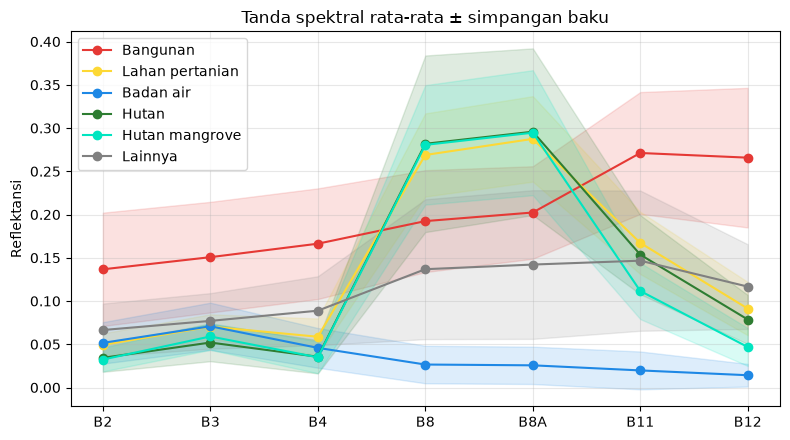

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for cid, (code_, label, color) in CLASSES.items():
    sub = df[df.class_id == cid][BAND_NAMES]
    m, s = sub.mean(), sub.std()
    
    ax.plot(BAND_NAMES, m, marker='o', color=color, label=label)
    ax.fill_between(BAND_NAMES, m - s, m + s, color=color, alpha=0.15)

ax.set_ylabel('Reflektansi')
ax.set_title('Tanda spektral rata-rata ± simpangan baku')
ax.legend(); ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/tanda_spektral.png', dpi=150)
plt.show()

In [17]:
# Seberapa baik tiap fitur memisahkan satu kelas dari sisanya (0.5 = tidak berguna, 1.0 = sempurna)
sep = pd.DataFrame({
    CLASSES[cid][1]: {f: max(roc_auc_score(df.class_id == cid, df[f]), 1 - roc_auc_score(df.class_id == cid, df[f])) for f in FEATURES}
    for cid in CLASSES
}).round(3)

display(sep)

,Bangunan,Lahan pertanian,Badan air,Hutan,Hutan mangrove,Lainnya
B2,0.965,0.567,0.510,0.793,0.786,0.677
B3,0.958,0.584,0.517,0.788,0.625,0.589
B4,0.975,0.601,0.612,0.792,0.747,0.748
B8,0.559,0.722,0.990,0.755,0.739,0.684
B8A,0.571,0.732,0.992,0.759,0.734,0.687
B11,0.948,0.653,0.988,0.575,0.666,0.517
B12,0.992,0.604,0.988,0.500,0.755,0.709
NDVI,0.715,0.612,0.982,0.886,0.816,0.700
NDWI,0.720,0.618,0.993,0.899,0.757,0.672
NDBI,0.949,0.600,0.544,0.731,0.918,0.821


In [18]:
# Khusus mangrove vs hutan
sub = df[df.class_id.isin([4, 5])]
mh = {f: max(roc_auc_score(sub.class_id == 5, sub[f]), 1 - roc_auc_score(sub.class_id == 5, sub[f])) for f in FEATURES}

print('Mangrove vs Hutan, fitur terbaik:')
print(pd.Series(mh).sort_values(ascending=False).round(3).head(8))

sep.to_csv(f'{OUT_DIR}/separabilitas_fitur.csv')

Mangrove vs Hutan, fitur terbaik:
MNDWI    0.923
B12      0.912
NDMI     0.903
NDBI     0.873
B11      0.801
B3       0.654
NDWI     0.591
NDVI     0.536
dtype: float64


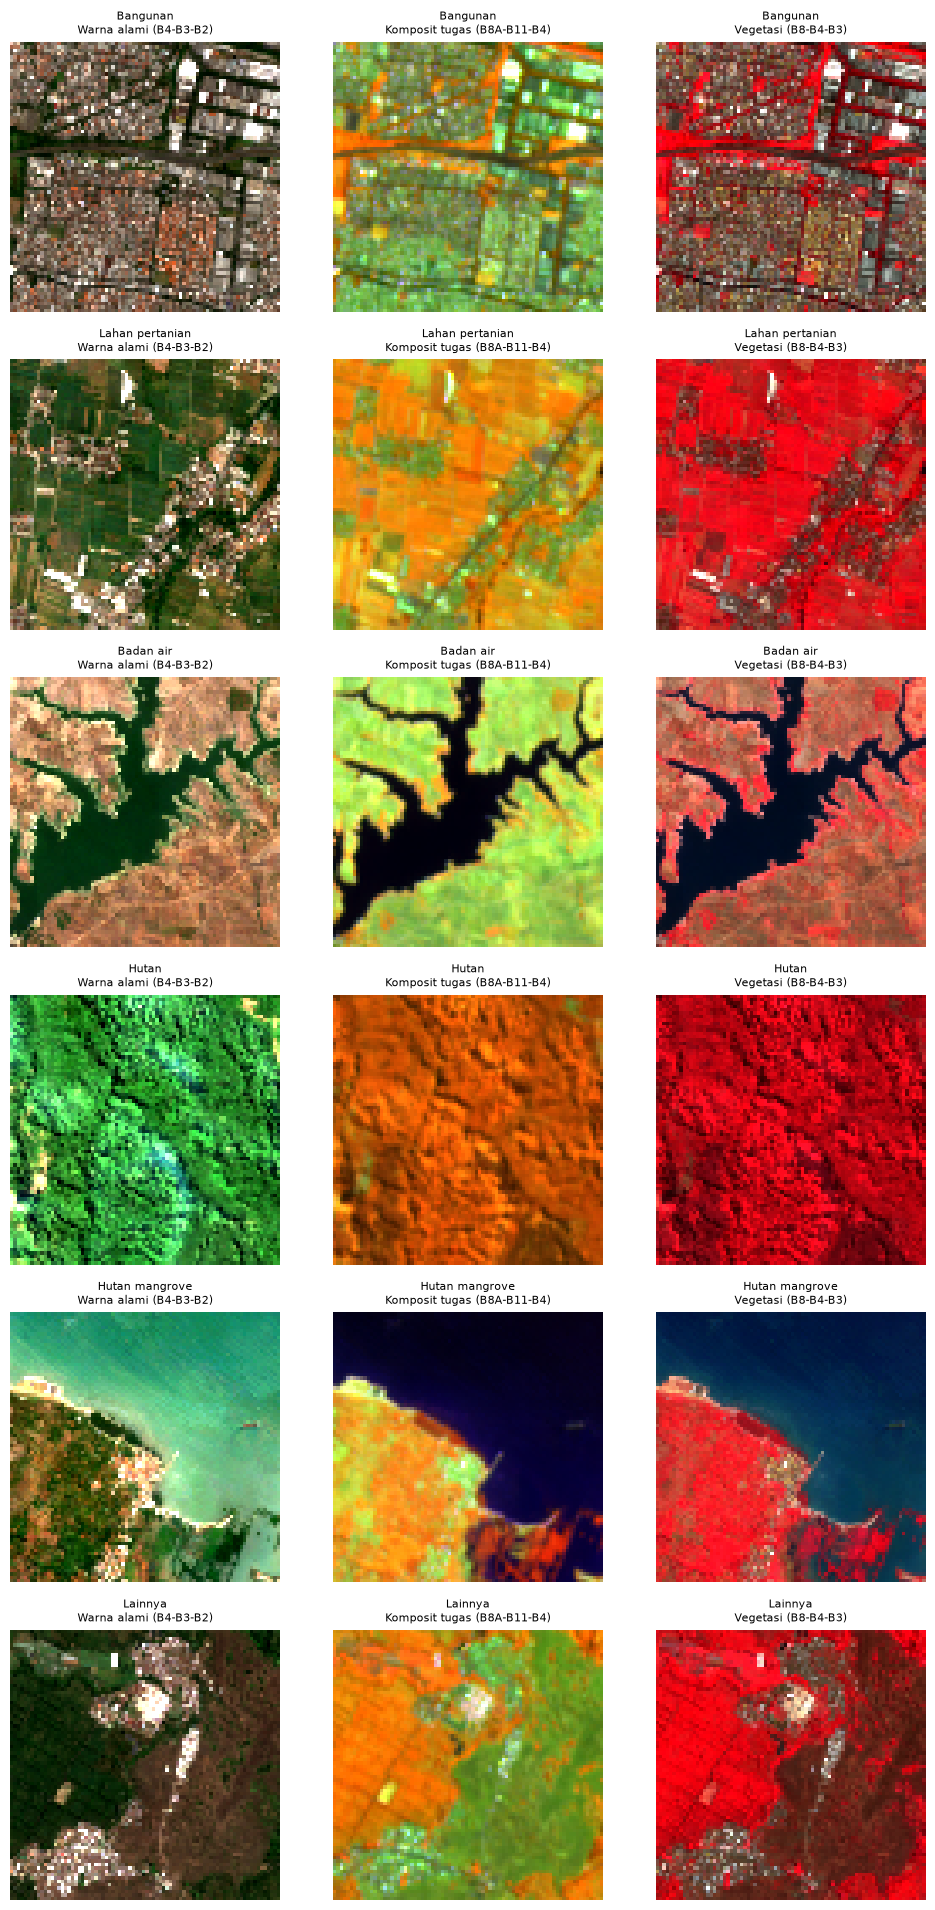

In [19]:
# Bandingkan komposit untuk satu contoh poligon per kelas
def window_around(src, geom, half=40):
    row, col = src.index(geom.centroid.x, geom.centroid.y)

    arr = src.read(window=Window(col - half, row - half, 2 * half, 2 * half), boundless=True,
                   fill_value=NODATA if NODATA is not None else 0).astype(np.float32)
    
    if NODATA is not None:
        arr[arr == NODATA] = np.nan

    return arr / SCALE

def comp(arr, bands):
    img = np.dstack([arr[BAND_NAMES.index(b)] for b in bands])
    lo, hi = np.nanpercentile(img, (2, 98))

    return np.clip((img - lo) / (hi - lo + 1e-9), 0, 1)

COMPS = {
    'Warna alami (B4-B3-B2)': ('B4', 'B3', 'B2'),
    f'Komposit tugas ({"-".join(RGB_ORDER)})': RGB_ORDER,
    'Vegetasi (B8-B4-B3)': ('B8', 'B4', 'B3')
}

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(10, 3.2 * len(CLASSES)))

with rasterio.open(RASTER) as src:
    for i, cid in enumerate(CLASSES):
        g = samples[samples.class_id == cid].sample(1, random_state=RANDOM_STATE).geometry.iloc[0]
        arr = window_around(src, g)

        for j, (title, bands) in enumerate(COMPS.items()):
            axes[i, j].imshow(comp(arr, bands)); axes[i, j].axis('off')
            axes[i, j].set_title(f'{CLASSES[cid][1]}\n{title}', fontsize=8)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/perbandingan_komposit.png', dpi=130)
plt.show()

#### Model dan Evaluasi

Data dibagi **per poligon** (bukan per piksel), supaya piksel bertetangga dari poligon yang sama tidak muncul di data latih dan uji sekaligus. Pembagian tetap menjaga proporsi kelas.

In [20]:
X = df[FEATURES].values.astype(np.float32)
y = df['class_id'].values - 1
g = df['poly_id'].values

# hold-out uji 20% poligon
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr, te = next(sgkf.split(X, y, g))
X_tr, X_te, y_tr, y_te, g_tr = X[tr], X[te], y[tr], y[te], g[tr]

print('piksel latih/uji :', len(tr), len(te))
print('poligon uji per kelas:\n', df.iloc[te].groupby('class').poly_id.nunique().to_string())

def make_model(name):
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE)
    
    return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                         tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE)

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []

for name in ['RandomForest', 'XGBoost']:
    res = cross_validate(make_model(name), X_tr, y_tr, groups=g_tr, cv=cv, scoring=['accuracy', 'f1_macro'])
    rows.append({'model': name, 'akurasi_cv': res['test_accuracy'].mean(), 'std': res['test_accuracy'].std(), 'f1_macro_cv': res['test_f1_macro'].mean()})

cv_table = pd.DataFrame(rows).round(4)

display(cv_table)

BEST = cv_table.sort_values('f1_macro_cv', ascending=False).iloc[0]['model']

print('Model terpilih:', BEST)

piksel latih/uji : 84666 21171
poligon uji per kelas:
 class
built_up    31
farmland    24
forest      22
mangrove    24
other       16
water       16


,model,akurasi_cv,std,f1_macro_cv
0,RandomForest,0.929,0.0121,0.9306
1,XGBoost,0.937,0.0116,0.9387


Model terpilih: XGBoost


Akurasi uji = 0.9209 | F1 macro = 0.9261

                 precision    recall  f1-score   support

       Bangunan      0.965     0.959     0.962      2508
Lahan pertanian      0.849     0.811     0.830      3673
      Badan air      0.980     0.989     0.984      3864
          Hutan      0.892     0.923     0.908      6046
 Hutan mangrove      0.962     0.938     0.950      1848
        Lainnya      0.926     0.921     0.924      3232

       accuracy                          0.921     21171
      macro avg      0.929     0.923     0.926     21171
   weighted avg      0.921     0.921     0.921     21171



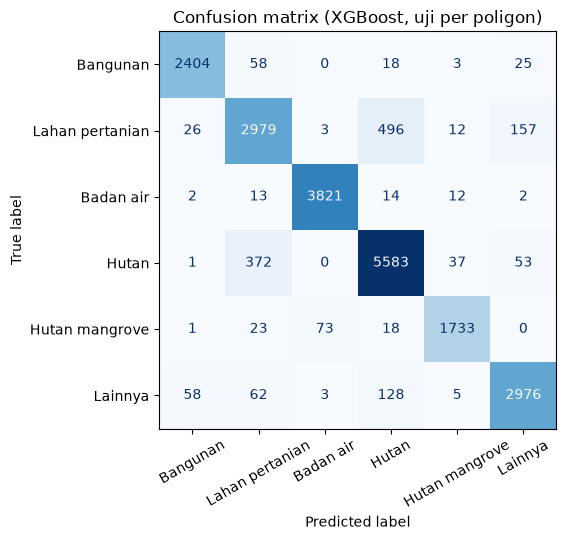

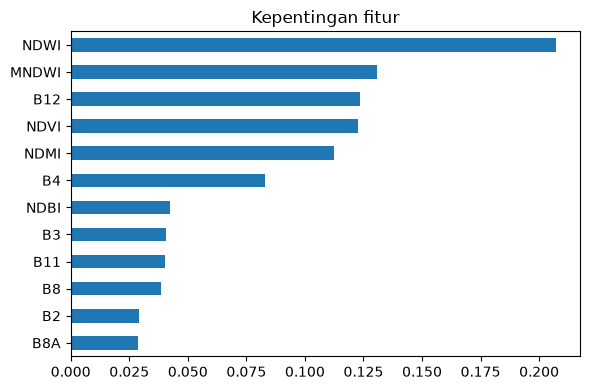

['openeo_out/model.joblib']

In [21]:
model = make_model(BEST).fit(X_tr, y_tr)
pred = model.predict(X_te)
acc = accuracy_score(y_te, pred)
f1m = f1_score(y_te, pred, average='macro')

print(f'Akurasi uji = {acc:.4f} | F1 macro = {f1m:.4f}\n')
print(classification_report(y_te, pred, labels=range(len(CLASSES)), target_names=NAMES, digits=3, zero_division=0))

cm = confusion_matrix(y_te, pred, labels=range(len(CLASSES)))
fig, ax = plt.subplots(figsize=(6.5, 5.5))

ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(ax=ax, cmap='Blues', xticks_rotation=30, colorbar=False)

ax.set_title(f'Confusion matrix ({BEST}, uji per poligon)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=150); plt.show()

imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()

imp.plot.barh(figsize=(6, 4), title='Kepentingan fitur'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/feature_importance.png', dpi=150); plt.show()

metrics = {
    'model': BEST, 'akurasi_uji': float(acc), 'f1_macro_uji': float(f1m),
    'cv': cv_table.to_dict('records'),
    'laporan': classification_report(y_te, pred, labels=range(len(CLASSES)), target_names=NAMES, output_dict=True, zero_division=0),
    'piksel_latih': int(len(tr)), 'piksel_uji': int(len(te)),
    'poligon_per_kelas': df.groupby('class').poly_id.nunique().to_dict(),
}

json.dump(metrics, open(f'{OUT_DIR}/metrics.json', 'w'), indent=2, ensure_ascii=False)

# model akhir untuk peta: dilatih ulang dengan SEMUA sampel (angka akurasi di atas tetap dari model hold-out)
final = make_model(BEST).fit(X, y)
joblib.dump(final, f'{OUT_DIR}/model.joblib')

#### Klasifikasi Seluruh Raster

In [22]:
CLS_TIF = f'{OUT_DIR}/klasifikasi_20m.tif'
ROWS = 256

with rasterio.open(RASTER) as src:
    profile = dict(driver='GTiff', height=src.height, width=src.width, count=1, dtype='uint8',
                   crs=src.crs, transform=src.transform, nodata=0, compress='deflate')
    
    counts = np.zeros(len(CLASSES) + 1, dtype=np.int64)

    with rasterio.open(CLS_TIF, 'w', **profile) as dst:
        for r0 in range(0, src.height, ROWS):
            h = min(ROWS, src.height - r0)
            win = Window(0, r0, src.width, h)
            arr = src.read(window=win)
            valid = np.ones(arr.shape[1:], bool) if NODATA is None else (arr != NODATA).all(axis=0)
            out = np.zeros(arr.shape[1:], np.uint8)

            if valid.any():
                refl = np.clip(arr[:, valid].astype(np.float32) / SCALE, 0, 1)
                out[valid] = final.predict(feature_stack(refl).T).astype(np.uint8) + 1

            counts += np.bincount(out.ravel(), minlength=len(CLASSES) + 1)
            dst.write(out, 1, window=win)

            if (r0 // ROWS) % 10 == 0:
                print(f'baris {r0}/{src.height}', end='\r')

px_km2 = R_RES[0] * R_RES[1] / 1e6

area = pd.DataFrame({'kelas': NAMES, 'kode': [CLASSES[i][0] for i in range(1, len(CLASSES) + 1)],
                     'piksel': counts[1:], 'luas_km2': (counts[1:] * px_km2).round(2)})

area['persen'] = (100 * area.piksel / area.piksel.sum()).round(2)

area.to_csv(f'{OUT_DIR}/luas_per_kelas.csv', index=False)
display(area)

,kelas,kode,piksel,luas_km2,persen
0,Bangunan,built_up,16868619,6747.45,5.90
1,Lahan pertanian,farmland,49109384,19643.75,17.18
2,Badan air,water,32785053,13114.02,11.47
3,Hutan,forest,49880895,19952.36,17.45
4,Hutan mangrove,mangrove,17150431,6860.17,6.00
5,Lainnya,other,119994685,47997.87,41.99


#### Poligon GeoJSON per Kelas (untuk Leaflet)

Hasil raster dibersihkan dari bercak kecil (`SIEVE_PX`), diubah jadi poligon, disederhanakan, dan disimpan per kelas dalam EPSG:4326.
Naikkan `SIEVE_PX` / `SIMPLIFY_M` kalau file terlalu besar.

In [23]:
# Buang bercak <50 piksel (= 2 ha)
SIEVE_PX = 50

# Penyerdehanaan garis (meter)
SIMPLIFY_M = 20

with rasterio.open(CLS_TIF) as src:
    cls = src.read(1); tfm = src.transform; crs = src.crs

cls = sieve(cls, size=SIEVE_PX, mask=cls > 0, connectivity=4)

recs = [(shape(geom), int(v)) for geom, v in shapes(cls, mask=cls > 0, transform=tfm)]
poly = gpd.GeoDataFrame({'class_id': [v for _, v in recs]}, geometry=[g_ for g_, _ in recs], crs=crs)

poly['class'] = poly.class_id.map(lambda i: CLASSES[i][0])
poly['label'] = poly.class_id.map(lambda i: CLASSES[i][1])
poly['luas_ha'] = (poly.geometry.area / 1e4).round(2)
poly['geometry'] = poly.geometry.simplify(SIMPLIFY_M, preserve_topology=True)

poly = poly.to_crs(4326)

try:
    poly['geometry'] = poly.geometry.set_precision(1e-5)     # kurangi digit koordinat -> file lebih kecil
except Exception:
    pass

for cid, (code_, label, _) in CLASSES.items():
    part = poly[poly.class_id == cid]
    path = f'{OUT_DIR}/hasil_{code_}.geojson'
    part.to_file(path, driver='GeoJSON')

    print(f'{label:18s} {len(part):7d} poligon  {os.path.getsize(path) / 1e6:7.1f} MB')

Bangunan             38386 poligon     38.9 MB
Lahan pertanian      43686 poligon     66.8 MB
Badan air             9066 poligon     13.6 MB
Hutan                40340 poligon     51.4 MB
Hutan mangrove       23160 poligon     16.0 MB
Lainnya              46969 poligon     44.7 MB
